In [36]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [37]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import splev, splrep

#import color_to_Teff_mc as ct
import photo_spec_teff as ps
import rest2012_joint_mcmc as jm
import rest2012_reddening_mcmc as rm
import rest2012_spectral_type as r12



In [38]:
from LC_utility import convert_Jy2mag
#from pdastro import *

In [39]:
pwd

'/Users/home/Documents/EtaCarEchoes/old_vers1'

In [40]:
ls data/filters

decam/


In [41]:
# Joint Mg+Ca reddening MCMC (rest2012_reddening_mcmc / joint summary)
EBV = 0.909
EBV_ERR = 0.018
RV = 4.8
LINE_TEFF = 5411.0
LINE_TEFF_ERR = 9.0


In [42]:
FILTER_DIR = Path(".data/filters/decam/")

In [43]:
def pickles_gi_calibration(filters, teffs, wave, flux):
    """Intrinsic (g-i)_0 vs Teff for Pickles I (monotonic, cooler = redder)."""
    tgrid = np.linspace(4000.0, 9000.0, 251)
    gi0 = np.empty_like(tgrid)
    for i, t in enumerate(tgrid):
        tmpl = jm.interp_template(float(t), teffs, flux)
        sg, _ = ps.band_signal(wave, tmpl, filters["g"], min_cov=0.7)
        si, _ = ps.band_signal(wave, tmpl, filters["i"], min_cov=0.7)
        gi0[i] = -2.5 * np.log10(sg / si)
    if not np.all(np.diff(gi0) < 0):
        raise RuntimeError("Pickles g-i is not monotonic in Teff")
    return tgrid, gi0



In [44]:
def pickles_gr_calibration(filters, teffs, wave, flux):
    """Intrinsic (g-i)_0 vs Teff for Pickles I (monotonic, cooler = redder)."""
    tgrid = np.linspace(4000.0, 9000.0, 251)
    gr0 = np.empty_like(tgrid)
    for i, t in enumerate(tgrid):
        tmpl = jm.interp_template(float(t), teffs, flux)
        sg, _ = ps.band_signal(wave, tmpl, filters["g"], min_cov=0.7)
        sr, _ = ps.band_signal(wave, tmpl, filters["r"], min_cov=0.7)
        gr0[i] = -2.5 * np.log10(sg / sr)
    if not np.all(np.diff(gi0) < 0):
        raise RuntimeError("Pickles g-i is not monotonic in Teff")
    return tgrid, gr0



In [45]:
def pickles_ri_calibration(filters, teffs, wave, flux):
    """Intrinsic (g-i)_0 vs Teff for Pickles I (monotonic, cooler = redder)."""
    tgrid = np.linspace(4000.0, 9000.0, 251)
    ri0 = np.empty_like(tgrid)
    for i, t in enumerate(tgrid):
        tmpl = jm.interp_template(float(t), teffs, flux)
        sr, _ = ps.band_signal(wave, tmpl, filters["r"], min_cov=0.7)
        si, _ = ps.band_signal(wave, tmpl, filters["i"], min_cov=0.7)
        ri0[i] = -2.5 * np.log10(sr / si)
    if not np.all(np.diff(gi0) < 0):
        raise RuntimeError("Pickles g-i is not monotonic in Teff")
    return tgrid, ri0


In [46]:
def band_extinctions(filters, teffs, wave, flux, ebv: float, rv: float = RV) -> dict[str, float]:
    """A_λ through each DECam band for a 5411 K Pickles I continuum."""
    tmpl = jm.interp_template(LINE_TEFF, teffs, flux)
    out = {}
    for band in "griz":
        s0, _ = ps.band_signal(wave, tmpl, filters[band], min_cov=0.7)
        s1, _ = ps.band_signal(
            wave, tmpl * rm.extinction_factor(wave, ebv, rv=rv), filters[band], min_cov=0.7
        )
        out[band] = float(-2.5 * np.log10(s1 / s0))
    return out


In [47]:
filters = ps.load_filters()

Text(0.5, 0, 'wavelength')

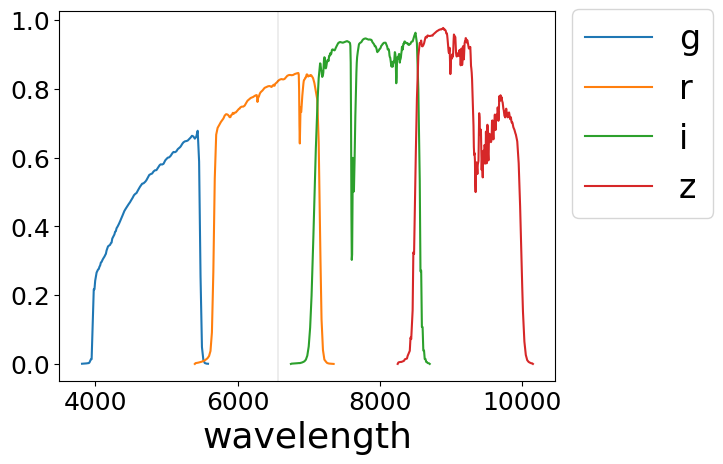

In [48]:
for band in "griz":

    plt.plot(filters[band][0], filters[band][1], label=band)

plt.legend(bbox_to_anchor=(1, 1.05))

plt.axvline(6563, c='k', lw=.1,) # H-alpha line

plt.xlabel('wavelength')

In [49]:

# spectra template 
# https://etc.stsci.edu/etcstatic/users_guide/1_ref_3_pickles.html?utm_source=chatgpt.com#
teffs, _, wave, flux = ps.template_library(filters)



In [50]:
wave

array([ 3500.,  3502.,  3504., ..., 10496., 10498., 10500.])

In [51]:
teffs

array([3990.25, 4123.  , 4255.98, 4591.98, 5046.61, 5320.  , 5508.08,
       6095.37, 6637.43, 7691.3 , 8700.  , 9727.47])

In [52]:
flux.shape

(12, 3501)

Text(0.5, 0, '')

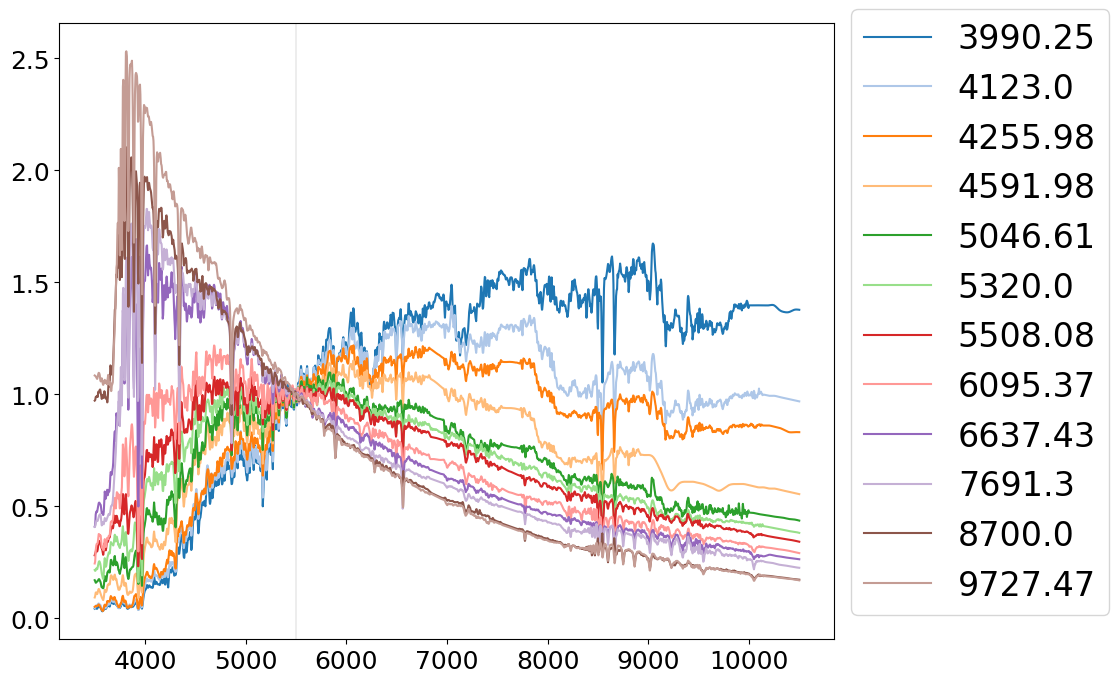

In [53]:
plt.figure(figsize=(10, 8))

for i in range(12):

    plt.plot(wave, flux[i], label=teffs[i], c=plt.cm.tab20(i))

plt.legend(bbox_to_anchor=(1, 1.05))

plt.axvline(5500, c='k', lw=.1,) # normalize 

plt.xlabel('')

In [54]:

# replace np.trapezoid with np.trapz for older numpy version
tgrid, gi0 = pickles_gi_calibration(filters, teffs, wave, flux)

tgrid, gr0 = pickles_gr_calibration(filters, teffs, wave, flux)

tgrid, ri0 = pickles_ri_calibration(filters, teffs, wave, flux)



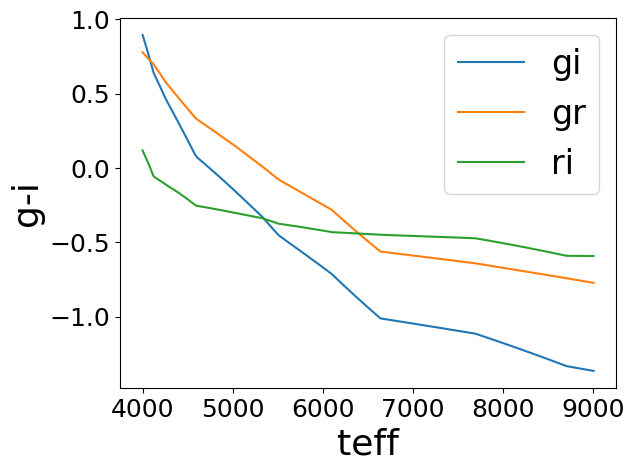

In [55]:
plt.plot(tgrid, gi0, label='gi')
plt.plot(tgrid, gr0, label='gr')
plt.plot(tgrid, ri0, label='ri')

plt.xlabel('teff')
plt.ylabel('g-i')
plt.legend()

In [56]:
def teff_from_gi(gi, tgrid, gi0):
    """Invert (g-i)_0 → Teff. gi0 decreases with Teff."""
    gi = np.asarray(gi, dtype=float)
    return np.interp(gi, gi0[::-1], tgrid[::-1], left=np.nan, right=np.nan)


In [57]:
EBV_ERR

0.018

In [58]:
EBV

0.909

In [59]:
A = band_extinctions(filters, teffs, wave, flux, EBV, RV)
A_hi = band_extinctions(filters, teffs, wave, flux, EBV + EBV_ERR, RV)
A_lo = band_extinctions(filters, teffs, wave, flux, EBV - EBV_ERR, RV)
e_gi = (A["g"] - A["i"])
de_gi = 0.5 * abs((A_hi["g"] - A_hi["i"]) - (A_lo["g"] - A_lo["i"]))

# Av = Rv * E(B-V)


In [60]:
A

{'g': 4.789150637953749,
 'r': 3.7618838863118143,
 'i': 2.9809967380470215,
 'z': 2.327752373745231}

### dereddenning

In [61]:
### Read in Models
#lcpath = './data/'
#lcpath = '../python_fitting/LC_tables/models/'

lcpath = '../emcee_fitting/LC_tables/models/'

#lcpath = './emcee_fitting/LC_tables/models/seperate_fit/' # path mcmc fit seperatelatey each bands, keep tshift same

# new model using MCMC
LCm2_i = pd.read_csv(lcpath +'iLC_mod2.csv')
LCm2_g = pd.read_csv(lcpath +'gLC_mod2.csv')
LCm2_r = pd.read_csv(lcpath +'rLC_mod2.csv')
LCm2_z = pd.read_csv(lcpath +'zLC_mod2.csv')

LCdat2_i = pd.read_csv(lcpath +'iLC_data2.csv')
LCdat2_g = pd.read_csv(lcpath +'gLC_data2.csv')
LCdat2_r = pd.read_csv(lcpath +'rLC_data2.csv')
LCdat2_z = pd.read_csv(lcpath +'zLC_data2.csv')



In [62]:
working_inds_i = np.where(LCm2_i['muJyas2']>0.)[0]
working_inds_g = np.where(LCm2_g['muJyas2']>0.)[0]
working_inds_r = np.where(LCm2_r['muJyas2']>0.)[0]
working_inds_z = np.where(LCm2_z['muJyas2']>0.)[0]

mag_i, mag_err_i = convert_Jy2mag(LCm2_i.loc[working_inds_i,'muJyas2'].values, LCm2_i.loc[working_inds_i,'muJyas2_err'].values)
mag_g, mag_err_g = convert_Jy2mag(LCm2_g.loc[working_inds_g,'muJyas2'].values, LCm2_g.loc[working_inds_g,'muJyas2_err'].values)
mag_r, mag_err_r = convert_Jy2mag(LCm2_r.loc[working_inds_r,'muJyas2'].values, LCm2_r.loc[working_inds_r,'muJyas2_err'].values)
mag_z, mag_err_z = convert_Jy2mag(LCm2_z.loc[working_inds_z,'muJyas2'].values, LCm2_z.loc[working_inds_z,'muJyas2_err'].values)

LCm2_i.loc[working_inds_i,'AB_mag'] = np.array(mag_i)
LCm2_i.loc[working_inds_i,'AB_mag_err'] = np.array(mag_err_i)
LCm2_g.loc[working_inds_g,'AB_mag'] = np.array(mag_g)
LCm2_g.loc[working_inds_g,'AB_mag_err'] = np.array(mag_err_g)
LCm2_r.loc[working_inds_r,'AB_mag'] = np.array(mag_r)
LCm2_r.loc[working_inds_r,'AB_mag_err'] = np.array(mag_err_r)
LCm2_z.loc[working_inds_z,'AB_mag'] = np.array(mag_z)
LCm2_z.loc[working_inds_z,'AB_mag_err'] = np.array(mag_err_z)


In [63]:
#t_ran = np.arange(54000, 63500)
t_ran = np.arange(54000, 62800)

g_new = splev(t_ran, splrep(LCm2_g.loc[working_inds_g,'mjd'], LCm2_g.loc[working_inds_g,'AB_mag'], k=1))
g_new_err = splev(t_ran, splrep(LCm2_g.loc[working_inds_g,'mjd'], LCm2_g.loc[working_inds_g,'AB_mag_err'], k=1))

r_new = splev(t_ran, splrep(LCm2_r.loc[working_inds_r,'mjd'], LCm2_r.loc[working_inds_r,'AB_mag'], k=1))
r_new_err = splev(t_ran, splrep(LCm2_r.loc[working_inds_r,'mjd'], LCm2_r.loc[working_inds_r,'AB_mag_err'], k=1))

i_new = splev(t_ran, splrep(LCm2_i.loc[working_inds_i,'mjd'], LCm2_i.loc[working_inds_i,'AB_mag'], k=1))
i_new_err = splev(t_ran, splrep(LCm2_i.loc[working_inds_i,'mjd'], LCm2_i.loc[working_inds_i,'AB_mag_err'], k=1))

z_new = splev(t_ran, splrep(LCm2_z.loc[working_inds_z,'mjd'], LCm2_z.loc[working_inds_z,'AB_mag'], k=1))
z_new_err = splev(t_ran, splrep(LCm2_z.loc[working_inds_z,'mjd'], LCm2_z.loc[working_inds_z,'AB_mag_err'], k=1))


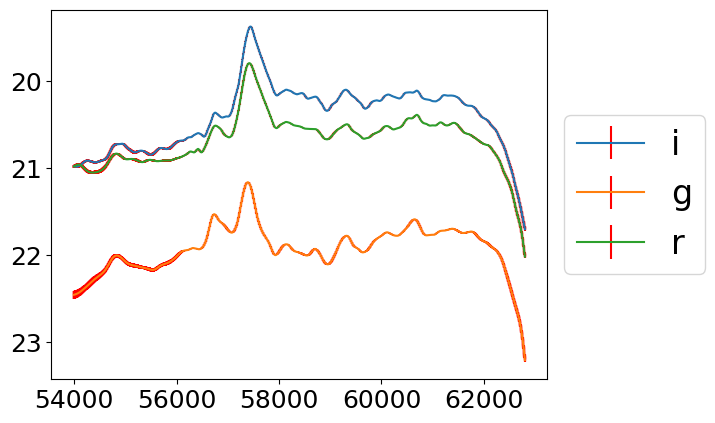

In [64]:
plt.errorbar(t_ran, i_new, i_new_err, ecolor='r', label='i')
plt.errorbar(t_ran, g_new, g_new_err, ecolor='r', label='g')
plt.errorbar(t_ran, r_new, r_new_err, ecolor='r', label='r')

plt.gca().invert_yaxis()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

In [65]:
g_new_dered, r_new_dered, i_new_dered, z_new_dered = g_new - A["g"], r_new - A["r"], i_new - A["i"], z_new - A["z"]


Text(0, 0.5, 'mag')

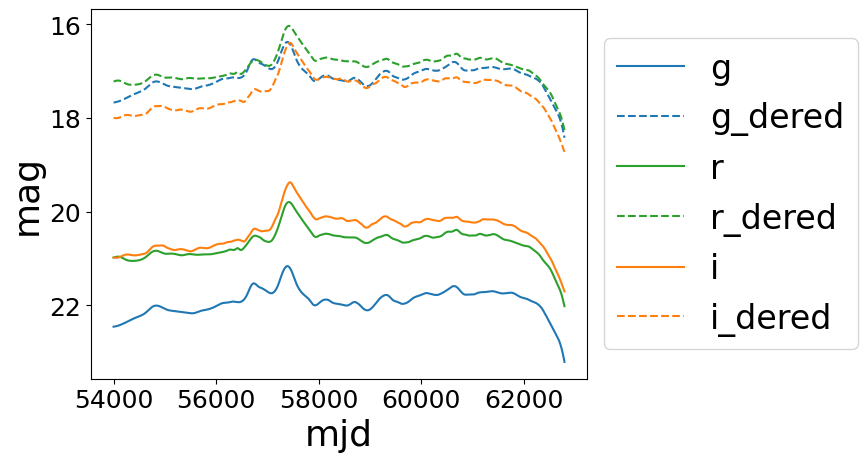

In [66]:

plt.plot(t_ran, g_new, '-', c=plt.cm.tab10(0), label='g')
plt.plot(t_ran, g_new_dered, '--', c=plt.cm.tab10(0), label='g_dered')

plt.plot(t_ran, r_new, '-', c=plt.cm.tab10(2), label='r')
plt.plot(t_ran, r_new_dered, '--', c=plt.cm.tab10(2), label='r_dered')

plt.plot(t_ran, i_new, '-', c=plt.cm.tab10(1), label='i')
plt.plot(t_ran, i_new_dered, '--', c=plt.cm.tab10(1), label='i_dered')


plt.gca().invert_yaxis()
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.xlabel('mjd')
plt.ylabel('mag')



In [67]:
gi_dered = g_new_dered - i_new_dered
gi_new = g_new-i_new

teff_gi = teff_from_gi(gi_dered, tgrid, gi0)



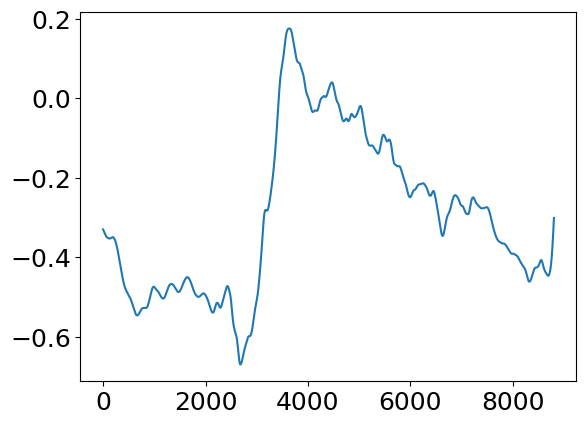

In [84]:
plt.plot(gi_dered)

In [68]:
gr_dered = g_new_dered - r_new_dered
gr_new = g_new-r_new
teff_gr = teff_from_gi(gr_dered, tgrid, gr0)


In [69]:
ri_dered = r_new_dered - i_new_dered
ri_new = r_new-i_new

teff_ri = teff_from_gi(ri_dered, tgrid, ri0)



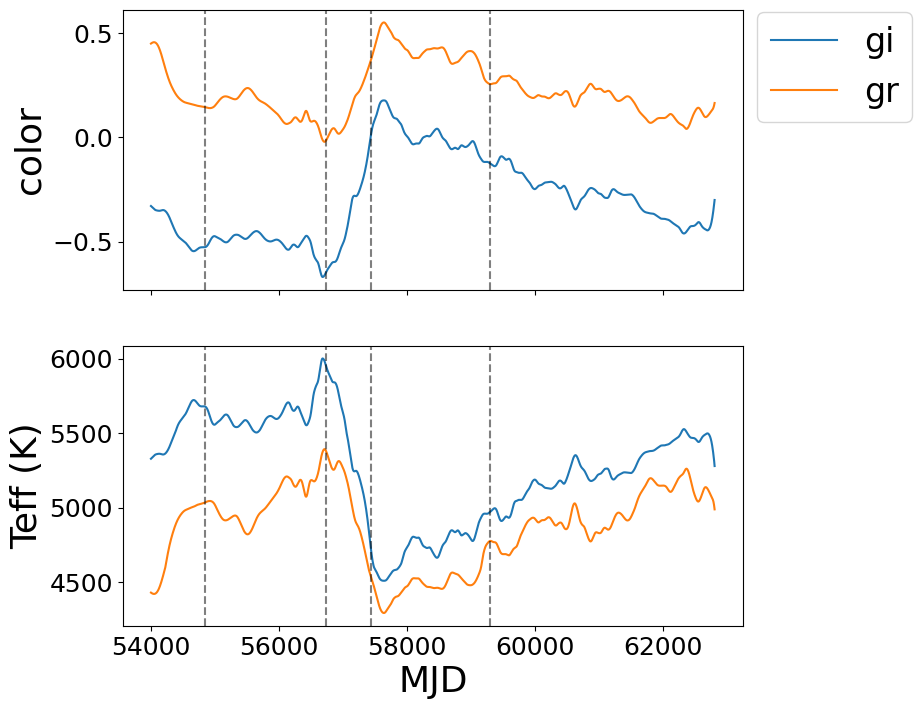

In [126]:

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(8, 8))


ax = axs[1]
ax.plot(t_ran, teff_gi, label='gi')
ax.plot(t_ran, teff_gr, label='gr')
ax.set_xlabel('MJD')
ax.set_ylabel('Teff (K)')

#-------------------
ax = axs[0]
ax.plot(t_ran, gi_dered, label='gi')
ax.plot(t_ran, gr_dered, label='gr')
#plt.plot(t_ran, teff_ri, label='ri')

#plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
#
#plt.xlabel('mjd')
#plt.ylabel('T(K)')
#
#plt.axvline( 54850, color='k', ls='--', alpha=0.5)
#plt.axvline( 56740, color='k', ls='--', alpha=0.5)
#plt.axvline( 57430, color='k', ls='--', alpha=0.5)
#plt.axvline( 59300, color='k', ls='--', alpha=0.5)

ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.05))
ax.set_ylabel('color')

#--------
for ax in axs:
    ax.axvline(54850, color='k', ls='--', alpha=0.5)
    ax.axvline(56740, color='k', ls='--', alpha=0.5)
    ax.axvline(57430, color='k', ls='--', alpha=0.5)
    ax.axvline(59300, color='k', ls='--', alpha=0.5)




## Radius

In [76]:
# Constants
R_sun = 6.957e10       # Solar radius in cm

T_sun = 5772           # Solar effective temperature in K
M_bol_sun = 4.74       # Solar bolometric magnitude

# Example bolometric correction function for i-band
def BC_i(T_eff):
    # assume linear and small
    #bc_i = 0.1 - 0.0001 * (T_eff - 5772)
    #return bc_i
    
    return 0

def radius_from_Mi_Teff(M_i, T_eff):
    """
    Compute stellar radius in solar radii from i-band magnitude and effective temperature.
    
    Parameters
    ----------
    M_i : float
        Absolute magnitude in i-band
    T_eff : float
        Effective temperature in Kelvin
    
    Returns
    -------
    R : float
        Stellar radius in solar radii
    """
    BC = BC_i(T_eff)
    log_R_Rsun = (M_bol_sun - M_i - BC)/5 - 2*np.log10(T_eff/T_sun)
    R = 10**log_R_Rsun
    
    return R


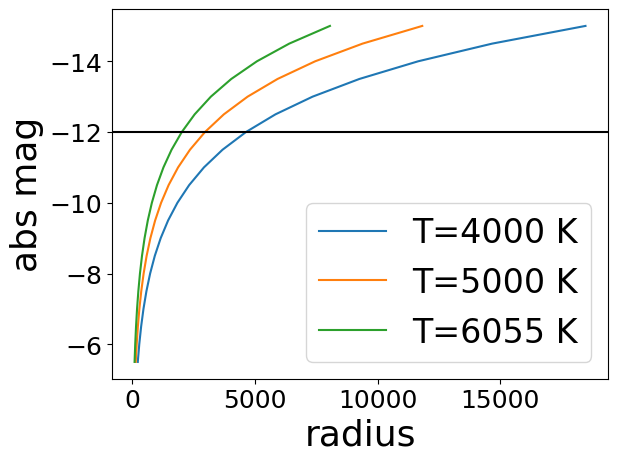

In [77]:
# radius, mag, temperature ralation

mags = np.arange(-15, -5, .5)

for ti in [4000, 5000, 6055]:
    r = radius_from_Mi_Teff(mags, ti,)

    plt.plot(r, mags, label=f'T={ti} K')

#plt.axvline(x=240, c='k')
plt.axhline(y=-12, c='k')
plt.xlabel('radius')
plt.ylabel('abs mag')
plt.gca().invert_yaxis()

plt.legend()


In [79]:
V_new = g_new_dered - 0.03 - 0.42*(g_new - r_new)

# 3rd peak 

# match absolute magnitude 
V_new.min() + 12 # apparent magnitude from historical record ~ -12


27.771900001035483

In [100]:
color_gi = g_new_dered - i_new_dered

#T = VI_to_Teff( gi_to_VI(color_gi) )

R_ec = radius_from_Mi_Teff(g_new_dered - 27.7, teff_gi)


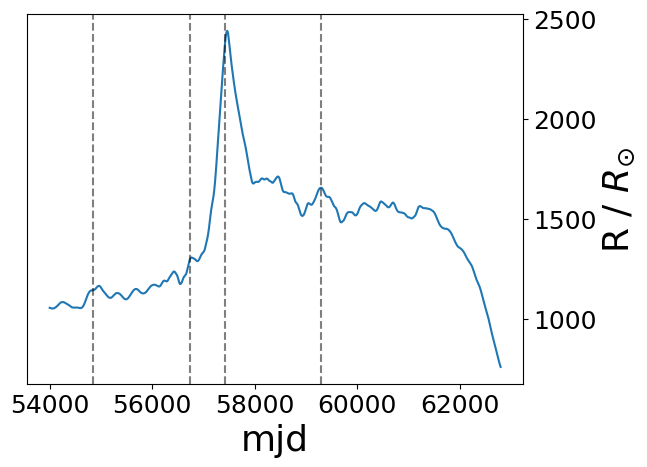

In [105]:
plt.plot(t, R_ec, )

plt.xlabel('mjd')
plt.ylabel(r'R / $R_{\odot}$')

ax = plt.gca()
# Move y-axis to the right
ax.yaxis.tick_right()                  # ticks on the right
ax.yaxis.set_label_position("right")   # label on the right

plt.axvline(54850, color='k', ls='--', alpha=0.5)
plt.axvline(56740, color='k', ls='--', alpha=0.5)
plt.axvline(57430, color='k', ls='--', alpha=0.5)
plt.axvline(59300, color='k', ls='--', alpha=0.5)


Text(0, 0.5, '')

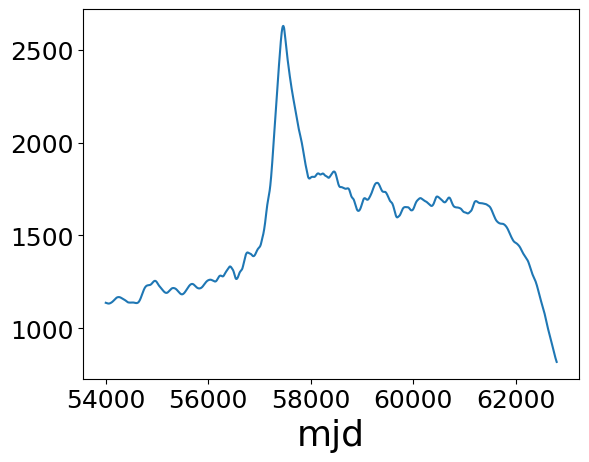

In [82]:
plt.plot(t_ran, R_ec)

plt.xlabel('mjd')
plt.ylabel('R')

## HR diagram

(-9.2, -11.8)

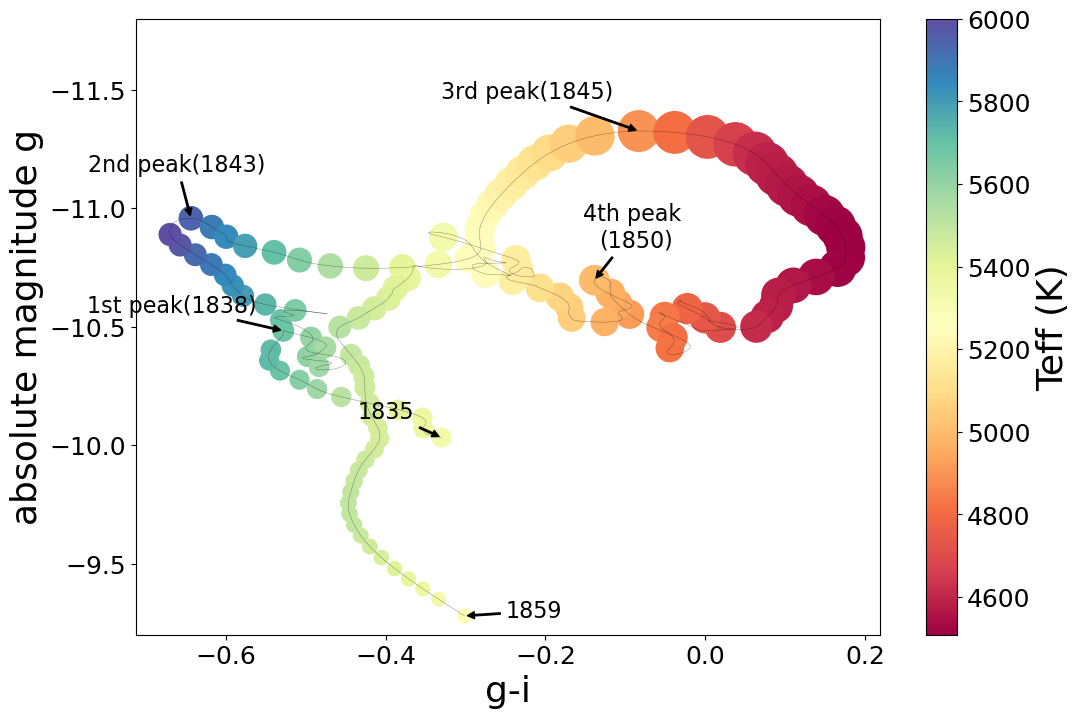

In [93]:
plt.figure(figsize=(12, 8))
#idx = t_ran < 64000

idx = t_ran < 62900

step = 1

color_gi = g_new_dered[idx][::step] - i_new_dered[idx][::step]

#color_gi = g_new[idx][::step] - z_new[idx][::step]

mag_i = g_new_dered[idx][::step] 
abs_mag_i = mag_i - 27.7

t = t_ran[idx][::step]

#T = VI_to_Teff( gi_to_VI(color_gi) )

T = teff_from_gi(color_gi, tgrid, gi0)


R_ec_bk = radius_from_Mi_Teff(abs_mag_i, T)

R_ec = R_ec_bk**2 / 615.132 /2

# plot the line
plt.plot(color_gi, abs_mag_i, '-', alpha=.5, c='k', lw=.3)

#plt.scatter(color_gi, abs_mag_i, s=1, c=T, cmap=plt.cm.Spectral)


#plt.scatter( T, abs_mag_i , alpha=0.4, s=R_ec/5, edgecolors='black',
#            c=t, cmap=plt.cm.Purples, )

color_gi_show = [color_gi[0], color_gi[-1]]
m_show = [abs_mag_i[0], abs_mag_i[-1]]
T_show = [T[0], T[-1]]
R_show = [R_ec[0], R_ec[-1]]

#values = np.array(t)
values = np.array(T)

# Normalize the array to range [0, 1] for the colormap
norm = (values - values.min()) / (values.max() - values.min())

# Get colors from the Purples colormap
#colors = plt.cm.Purples(0.5+0.5*norm)

colors = plt.cm.Spectral(norm)
#colors = plt.cm.RdBu(norm)
#---------------------------------------------------
# plot the first dot

x_first = color_gi[0]
y_first = abs_mag_i[0]

#plt.scatter(x_first, y_first, s=R_ec[0]/5, color=colors[0]);

plt.annotate('1835', fontsize=16,
            xy=(x_first, y_first), xycoords='data',
            xytext=(-40, 10), textcoords='offset points',
            arrowprops=dict(facecolor='black', arrowstyle='simple, head_length=1, head_width=1', mutation_scale=5),
            horizontalalignment='center', verticalalignment='bottom')

#------------------
# plot peaks
mjd_peak1 = 54890 - 60
idx_peak1 = np.argmin(np.abs(t_ran[::step] - mjd_peak1))

x_peak1 = color_gi[idx_peak1]
y_peak1 = abs_mag_i[idx_peak1]


#plt.text(x_peak1+600, y_peak1-0.1, '1st peak(1838)', c='k', fontsize=16)
#plt.arrow(x_peak1, y_peak1, 0, -0.1, head_width=0.05, head_length=0.05,)

#plt.scatter(x_peak1, y_peak1, s=R_ec[idx_peak1]/5, color=colors[idx_peak1])

color_gi_show.append(x_peak1)
m_show.append(y_peak1)
T_show.append(T[idx_peak1])
R_show.append(R_ec[idx_peak1])

plt.annotate('1st peak(1838)', fontsize=16,
            xy=(x_peak1, y_peak1), xycoords='data',
            xytext=(-80, 10), textcoords='offset points',
            arrowprops=dict(facecolor='black', arrowstyle='simple, head_length=1, head_width=1', mutation_scale=5),
            horizontalalignment='center', verticalalignment='bottom')

#---------------------

mjd_peak1 = 56690 + 50
idx_peak1 = np.argmin(np.abs(t_ran[::step] - mjd_peak1))
x_peak1 = color_gi[idx_peak1]
y_peak1 = abs_mag_i[idx_peak1]
#plt.scatter(x_peak1, y_peak1, s=R_ec[idx_peak1]/5, color=colors[idx_peak1])

#plt.text(x_peak1+200, y_peak1+0.2, '2nd peak(1843)', c='k', fontsize=16)
#plt.arrow(x_peak1, y_peak1, 0, 0.2)

color_gi_show.append(x_peak1)
m_show.append(y_peak1)
T_show.append(T[idx_peak1])
R_show.append(R_ec[idx_peak1])

plt.annotate('2nd peak(1843)', fontsize=16,
            xy=(x_peak1, y_peak1), xycoords='data',
            xytext=(-10, 30), textcoords='offset points',
            arrowprops=dict(facecolor='black', arrowstyle='simple, head_length=1, head_width=1', mutation_scale=5),
            horizontalalignment='center', verticalalignment='bottom')

#------------------

#------------------------
mjd_peak1 = 57388
idx_peak1 = np.argmin(np.abs(t_ran[::step] - mjd_peak1))

x_peak1 = color_gi[idx_peak1]
y_peak1 = abs_mag_i[idx_peak1]

#plt.scatter(x_peak1, y_peak1, s=R_ec[idx_peak1]/5, color=colors[idx_peak1])

#plt.text(x_peak1, y_peak1-0.5, '3rd peak(1845)', c='k', fontsize=16)
#plt.arrow(x_peak1, y_peak1, 0, -0.5)

color_gi_show.append(x_peak1)
m_show.append(y_peak1)
T_show.append(T[idx_peak1])
R_show.append(R_ec[idx_peak1])

plt.annotate('3rd peak(1845)', fontsize=16,
            xy=(x_peak1, y_peak1), xycoords='data',
            xytext=(-80, 20), textcoords='offset points',
            arrowprops=dict(facecolor='black', arrowstyle='simple, head_length=1, head_width=1', mutation_scale=5),
            horizontalalignment='center', verticalalignment='bottom')

#-------------------------
#mjd_peak1 = 59300
mjd_peak1 = 59360

idx_peak1 = np.argmin(np.abs(t_ran[::step] - mjd_peak1))

idx_peak1 = np.argmin(np.abs(t_ran[::step] - mjd_peak1))

x_peak1 = color_gi[idx_peak1]
y_peak1 = abs_mag_i[idx_peak1]
#plt.scatter(x_peak1, y_peak1, s=R_ec[idx_peak1]/5, color=colors[idx_peak1])

#plt.text(x_peak1, y_peak1+0.2, '4th peak (1850)', c='k', fontsize=16)
#plt.arrow(x_peak1, y_peak1, 0, 0.2)

color_gi_show.append(x_peak1)
m_show.append(y_peak1)
T_show.append(T[idx_peak1])
R_show.append(R_ec[idx_peak1])

plt.annotate('4th peak \n(1850)', fontsize=16,
            xy=(x_peak1, y_peak1), xycoords='data',
            xytext=(30, 20), textcoords='offset points',
            arrowprops=dict(facecolor='black', arrowstyle='simple, head_length=1, head_width=1', mutation_scale=5),
            horizontalalignment='center', verticalalignment='bottom')


# plot the last dot
x_last = color_gi[-1]
y_last = abs_mag_i[-1]
#plt.scatter(x_last, y_last, s=R_ec[-1]/5, color=colors[-1]);

plt.annotate('1859', fontsize=16,
            xy=(x_last, y_last), xycoords='data',
            xytext=(50, -5), textcoords='offset points',
            arrowprops=dict(facecolor='black', arrowstyle='simple, head_length=1, head_width=1', mutation_scale=5),
            horizontalalignment='center', verticalalignment='bottom')


#--------------------------------------------------

# plot all, remove overlaps by distance
for color, color_gi_i, m_i, R_i, T_i in zip(colors[1:], color_gi[1:], abs_mag_i[1:], R_ec[1:], T[1:]):
    color_gi_show_arr = np.array(color_gi_show)
    m_show_arr = np.array(m_show)
    dist = ((color_gi_i - color_gi_show_arr) )**2 + (m_i - m_show_arr)**2
    
    if min(dist[dist>0])>.002:
        #sc = plt.scatter(color_gi_i, m_i, s=R_i/5, color=color);
        #print('plot')
        color_gi_show.append(color_gi_i)
        m_show.append(m_i)

        T_show.append(T_i)
        R_show.append(R_i)


color_gi_show_arr = np.array(color_gi_show)
m_show_arr = np.array(m_show)

R_show_arr = np.array(R_show)
T_show_arr = np.array(T_show)

#sc = plt.scatter(color_gi_show_arr_, m_show_arr_, s=R_show_arr/5, color=color_show);

#sc = plt.scatter(color_gi_show_arr_, m_show_arr_, s=R_show_arr/5, c=T_, cmap=plt.cm.Spectral);



sc = plt.scatter(color_gi_show_arr, m_show_arr, s=R_show_arr/5, c=T_show_arr, cmap=plt.cm.Spectral);

cbar = plt.colorbar(sc, ax=plt.gca())
#cbar.set_ticks([4000, 6000])
cbar.set_label("Teff (K)")
#--------------------------------------------------
plt.gca().invert_yaxis()
#plt.gca().invert_xaxis()

plt.xlabel('g-i');
plt.ylabel('absolute magnitude g')

plt.ylim([-9.2, -11.8])

#plt.xlim([0.6, 2.35])


#plt.xlim([0.8, 2.1])


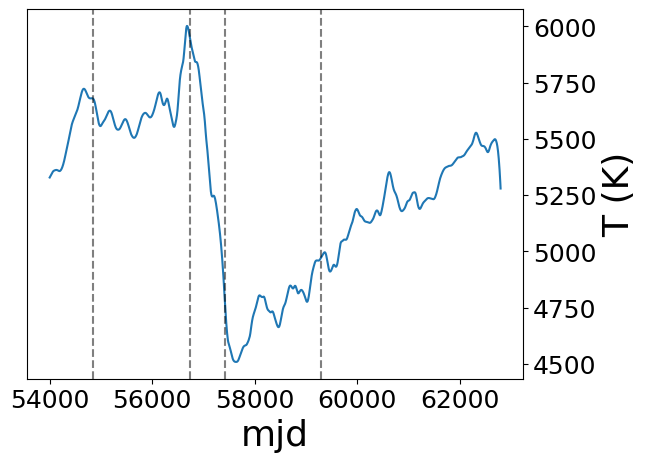

In [94]:
plt.plot(t, T, )

plt.xlabel('mjd')
plt.ylabel('T (K)')

ax = plt.gca()
# Move y-axis to the right
ax.yaxis.tick_right()                  # ticks on the right
ax.yaxis.set_label_position("right")   # label on the right

plt.axvline(54850, color='k', ls='--', alpha=0.5)
plt.axvline(56740, color='k', ls='--', alpha=0.5)
plt.axvline(57430, color='k', ls='--', alpha=0.5)
plt.axvline(59300, color='k', ls='--', alpha=0.5)


### proposal plot

In [61]:
from LC_utility import *
from pdastro import *

In [ ]:
plt.rcParams['axes.labelsize'] =  26     # size of x/y labels
plt.rcParams['xtick.labelsize'] = 18   # size of tick labels
plt.rcParams['ytick.labelsize'] = 18
plt.rcParams['legend.fontsize'] = 24

In [62]:
### historical LC
eta_historic = pdastrostatsclass()
eta_historic.load('./eta_full_revisedLC.txt', header=None, namesMapping={0:'Author',1:'Year',2:'Mag',3:'Mag_err'})

lc_flux_counts = 10 ** (-0.4 * (eta_historic.t['Mag']))
lc_flux_err = 0.921 * lc_flux_counts * eta_historic.t['Mag_err']
lc_mjd = Time(eta_historic.t['Year'].values, format='decimalyear', scale='utc').mjd + 57339 + 5068

eta_historic.t['Flux'] = lc_flux_counts
eta_historic.t['Flux_err'] = lc_flux_err
eta_historic.t['MJD'] = lc_mjd

/Users/home/Documents/EtaCarEchoes/old_vers1/pdastro.py:204: FutureWarning: The 'delim_whitespace' keyword in pd.read_table is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  self.t = pd.read_table(filename,delim_whitespace=delim_whitespace,**kwargs)
/Users/home/miniconda3/envs/datasci/lib/python3.10/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "dtf2d" yielded 520 of "dubious year (Note 6)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/home/miniconda3/envs/datasci/lib/python3.10/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 520 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/Users/home/miniconda3/envs/datasci/lib/python3.10/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 520 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


(1836.1, 1865.6)

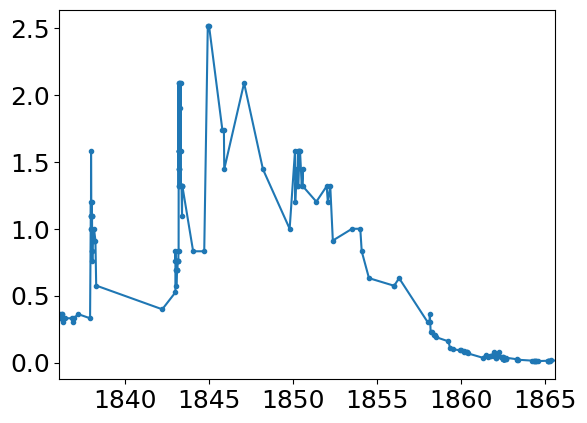

In [63]:
x = eta_historic.t['Year']
y = eta_historic.t['Flux']

y_err = eta_historic.t['Flux_err']
plt.plot(x, y, '.-')

plt.xlim(1836.1, 1865.6)


In [65]:
LCm2_g

,mjd,muJyas2,muJyas2_err,phase,AB_mag,AB_mag_err
0,53044.369999,5.242366,0.267675,-4399.911707,22.101182,0.055451
1,53046.889893,5.236889,0.262847,-4397.391812,22.102317,0.054508
2,53049.409788,5.231404,0.258084,-4394.871917,22.103454,0.053576
3,53051.929683,5.225910,0.253389,-4392.352022,22.104595,0.052657
4,53054.449578,5.220409,0.248762,-4389.832127,22.105739,0.051750
...,...,...,...,...,...,...
4995,65631.244631,-0.046727,0.085816,8186.962926,NaN,NaN
4996,65633.764526,-0.042025,0.088912,8189.482821,NaN,NaN
4997,65636.284421,-0.037322,0.092125,8192.002715,NaN,NaN
4998,65638.804315,-0.032621,0.095450,8194.522610,NaN,NaN


In [70]:
from astropy.time import Time
#t_ran_year = Time(t_ran, format='mjd', scale='utc').decimalyear

In [93]:
def phase_to_historic_year(x):
    return 1845 + x

def historic_year_to_phase(x):
    return x-1845



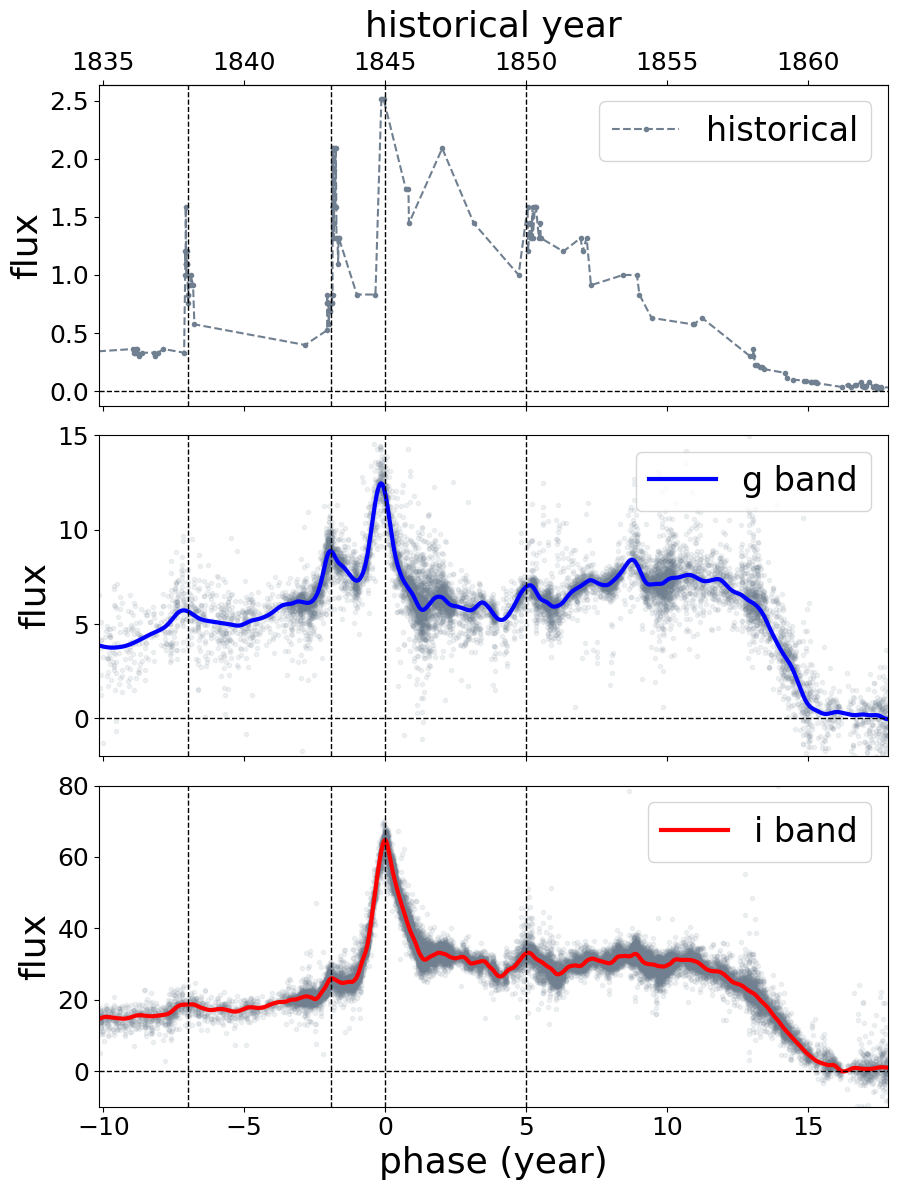

In [228]:

fig, axs = plt.subplots(3, 1, figsize=(9, 12), sharex=True)

ax = axs[0]

peak_t = 2016.15

x = eta_historic.t['Year'] + 171.1 - peak_t
y = eta_historic.t['Flux']

y_err = eta_historic.t['Flux_err']
ax.plot(x, y, '.--', color='slategray', label='historical')
ax.set_xlim(2006-peak_t, 2034-peak_t)

ax.set_ylabel('flux')


ax_top = ax.secondary_xaxis(
    'top',
    functions=(phase_to_historic_year, historic_year_to_phase)
)
ax_top.set_xlabel("historical year", labelpad=10);
ax_top.set_xticks([1835, 1840, 1845, 1850, 1855, 1860]);



# ----------------

ax = axs[1]

LCdat2_g['year'] = Time(LCdat2_g['mjd'], format='mjd', scale='utc').decimalyear - peak_t

df = LCdat2_g
ax.plot(df['year'], df['muJyas2'], '.', alpha=0.1, color='slategray' )


LCm2_g['year'] = Time(LCm2_g['mjd'], format='mjd', scale='utc').decimalyear - peak_t


df = LCm2_g
ax.plot(df['year'], df['muJyas2'], '-', lw=3, alpha=1, color='b', label='g band')

ax.set_ylabel('flux')
ax.set_ylim([-2, 15])
# ----------------

ax = axs[2]

LCdat2_i['year'] = Time(LCdat2_i['mjd'], format='mjd', scale='utc').decimalyear - peak_t

df = LCdat2_i
ax.plot(df['year'], df['muJyas2'], '.', alpha=0.1, color='slategray' )


LCm2_i['year'] = Time(LCm2_i['mjd'], format='mjd', scale='utc').decimalyear - peak_t


df = LCm2_i
ax.plot(df['year'], df['muJyas2'], '-', lw=3, alpha=1, color='r', label='i band')

ax.set_ylabel('flux')
ax.set_ylim([-10, 80])

ax.set_xlabel('phase (year)')
# ----------------

for ax in axs:
    ax.axhline(y=0, ls='--', c='k', lw=1)
    ax.axvline(x=0, ls='--', c='k', lw=1)
    ax.axvline(x=0-1.9, ls='--', c='k', lw=1)
    ax.axvline(x=0-7, ls='--', c='k', lw=1)
    ax.axvline(x=0+5, ls='--', c='k', lw=1)
    ax.legend(loc='upper right')

fig.tight_layout()

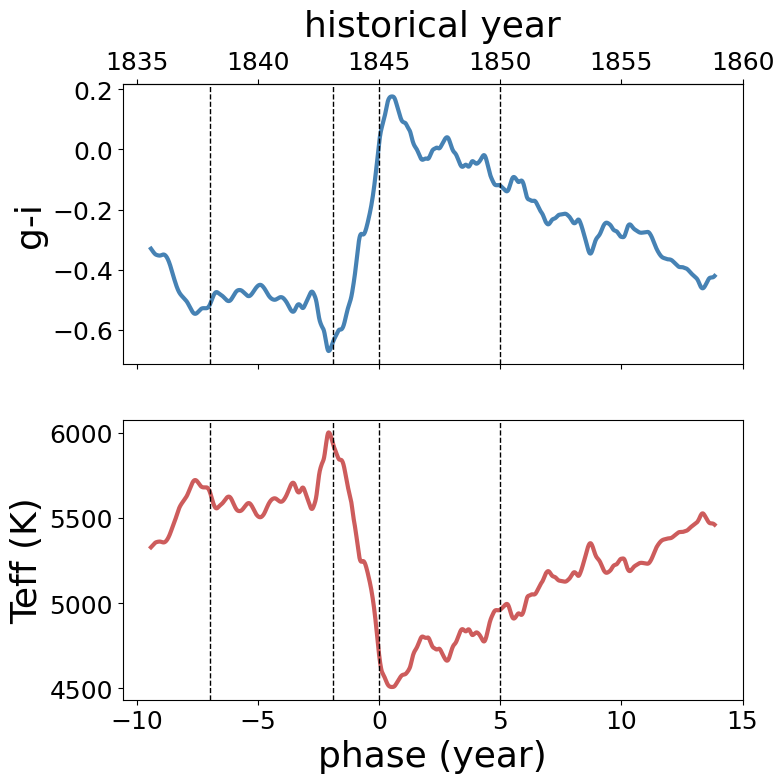

In [232]:
fig, axs = plt.subplots(2, 1, figsize=(8, 8), sharex=True)


t_ran_year = Time(t_ran, format='mjd', scale='utc').decimalyear


ax = axs[0]
idx = t_ran_year < 2030
ax.plot(t_ran_year[idx] - peak_t, gi_dered[idx],  c='steelblue', lw=3)

ax.set_ylabel('g-i')

ax_top = ax.secondary_xaxis(
    'top',
    functions=(phase_to_historic_year, historic_year_to_phase)
)
ax_top.set_xlabel("historical year", labelpad=10);
ax_top.set_xticks([1835, 1840, 1845, 1850, 1855, 1860]);


ax = axs[1]

plt.plot(t_ran_year[idx] - peak_t, teff_gi[idx], c='indianred', lw=3)

ax.set_xlabel('phase (year)')
ax.set_ylabel('Teff (K)')

for ax in axs:
    ax.axvline(x=0, ls='--', c='k', lw=1)
    ax.axvline(x=0-1.9, ls='--', c='k', lw=1)
    ax.axvline(x=0-7, ls='--', c='k', lw=1)
    ax.axvline(x=0+5, ls='--', c='k', lw=1)



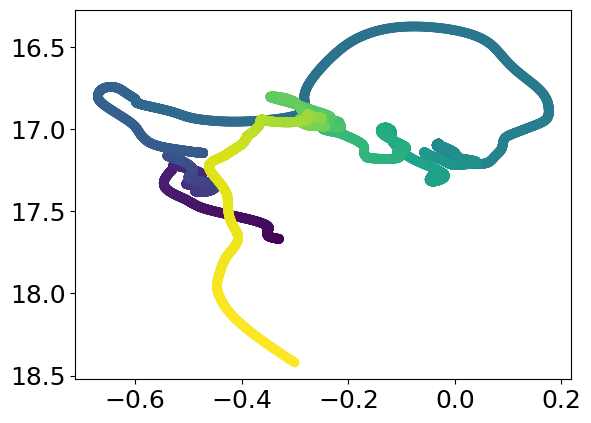

In [223]:
plt.scatter(gi_dered, g_new_dered, c=t_ran)

plt.gca().invert_yaxis()

Text(0, 0.5, 'Teff (K)')

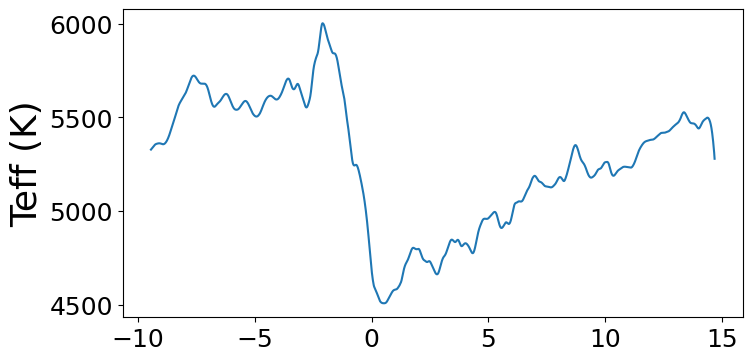

In [100]:
plt.figure(figsize=(8, 4))

t_ran_year = Time(t_ran, format='mjd', scale='utc').decimalyear

plt.plot(t_ran_year - peak_t, teff_gi)



plt.ylabel('Teff (K)')


Charlie

In [ ]:
    filters = ps.load_filters()
    teffs, _, wave, flux = ps.template_library(filters)
    tgrid, gi0 = pickles_gi_calibration(filters, teffs, wave, flux)

    A = band_extinctions(filters, teffs, wave, flux, EBV, RV)
    A_hi = band_extinctions(filters, teffs, wave, flux, EBV + EBV_ERR, RV)
    A_lo = band_extinctions(filters, teffs, wave, flux, EBV - EBV_ERR, RV)
    e_gi = (A["g"] - A["i"])
    de_gi = 0.5 * abs((A_hi["g"] - A_hi["i"]) - (A_lo["g"] - A_lo["i"]))

    t, g, ge, r, re, i, ie, z, ze = load_light_curves()
    g0, r0, i0, z0 = g - A["g"], r - A["r"], i - A["i"], z - A["z"]

    gi = g0 - i0
    gr = g0 - r0
    ri = r0 - i0
    iz = i0 - z0
    gi_err_phot = np.sqrt(ge**2 + ie**2)
    gi_err = np.sqrt(gi_err_phot**2 + de_gi**2 + GI_SYS**2)
    gr_err = np.sqrt(ge**2 + re**2 + GI_SYS**2)
    ri_err = np.sqrt(re**2 + ie**2)
    iz_err = np.sqrt(ie**2 + ze**2)

    teff = teff_from_gi(gi, tgrid, gi0)
    teff_lo = teff_from_gi(gi + gi_err, tgrid, gi0)  # redder → cooler
    teff_hi = teff_from_gi(gi - gi_err, tgrid, gi0)
